# Chord Data Analysis

In [1]:
import os
import sys
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath(os.path.join('..')))

from src.plot_data import plot_chord_distribution

## Data Preparation

In [2]:
chordlab_path = "../data/beatles/annotations/chordlab/The Beatles/"

lab_files = glob.glob(os.path.join(chordlab_path, "**/*.lab"), recursive=True)

print(f"{len(lab_files)} annotated songs found.")

data = []

for file in lab_files:
    song_name = os.path.basename(file).replace(".lab", "")
    with open(file, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 3:
                start = float(parts[0])
                end = float(parts[1])
                chord = parts[2]
                duration = end - start
                
                data.append({
                    "song": song_name,
                    "start": start,
                    "end": end,
                    "duration": duration,
                    "chord": chord
                })

df = pd.DataFrame(data)

print("\n--- Parsed data preview ---")
print(df.head())

180 annotated songs found.

--- Parsed data preview ---
                     song      start        end  duration chord
0  13_-_What_You're_Doing   0.000000   0.421247  0.421247     N
1  13_-_What_You're_Doing   0.421247   7.525011  7.103764     N
2  13_-_What_You're_Doing   7.525011   9.370997  1.845986     D
3  13_-_What_You're_Doing   9.370997  11.124104  1.753107     G
4  13_-_What_You're_Doing  11.124104  12.935260  1.811156     D


In [3]:
df['clean_chord'] = df['chord'].apply(lambda x: x.split('/')[0] if '/' in x else x)

print(f"\nTotal number of chord changes analyzed: {len(df)}")
print(f"Number of unique chords found: {df['clean_chord'].nunique()}")


Total number of chord changes analyzed: 14621
Number of unique chords found: 247


## Visualization

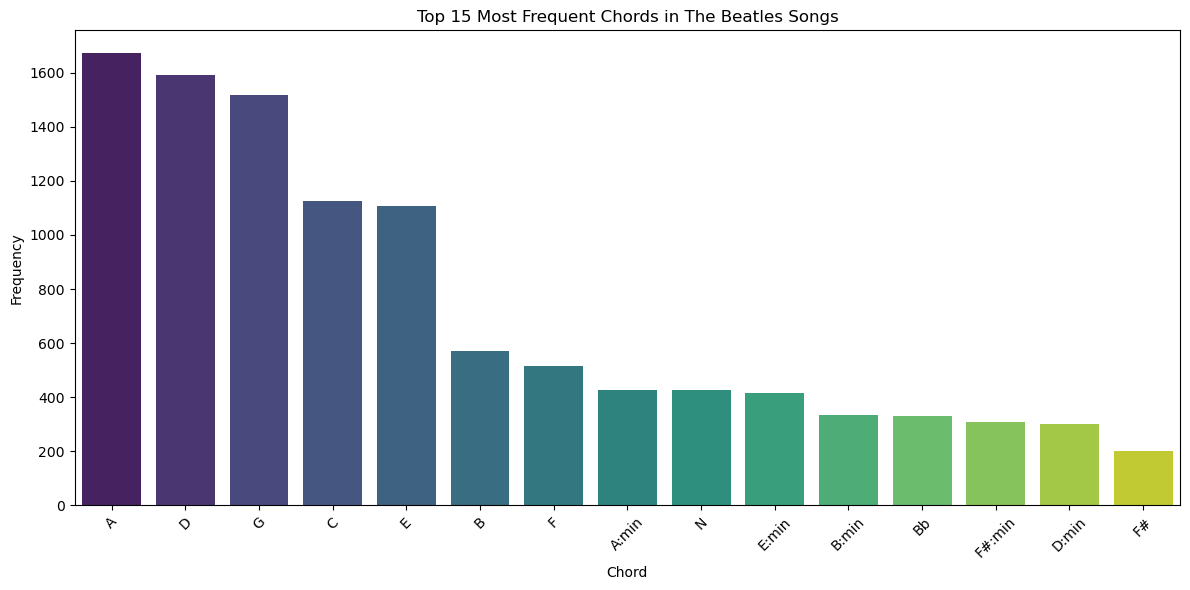

In [4]:
plot_chord_distribution(df, top_n=15)

In [5]:
print("\n--- Chord length stats (seconds) ---")
print(df['duration'].describe())


--- Chord length stats (seconds) ---
count    14621.000000
mean         2.006230
std          2.562814
min          0.016849
25%          1.056508
50%          1.625397
75%          2.125385
max        137.422406
Name: duration, dtype: float64
